# Solar System Visibility Checker
A companion to `target_visibility.ipynb` for planets and their major moons, whose positions come from [JPL Horizons](https://ssd.jpl.nasa.gov/horizons/) instead of a fixed sky coordinate.

- **Cell 1**: imports. The helper functions live in `helpers.py` and `solar_system_helpers.py` beside this notebook.
- **Cell 2**: everything you edit: `targets_list`, the UTC start/stop, the cadence, the TLE and the `Visibility` settings.
- **Cell 3**: ephemerides of every body in each target's system from Horizons, with how often each moon is free and clear.
- **Cell 4**: visibility per target, one best-roll search per day.
- **Cell 5**: the pointing RA and Dec over time (also as a J2000 ECI unit vector x, y, z), and how far each body of the system is from the target.
- **Cell 6**: one timeline per target: when it is visible, and when each body of its system is free and clear.
- **Cell 7**: which pointing constraint is failing while the target is not visible.
- **Cell 8**: the simulated NIRDA subarray each day, at the roll held that day.
- **Cell 9**: the simulated VISDA star field each day, at the roll held that day.
- **Cell 10**: one CSV per target of visibility, pointing and roll at every time step.

A target can be a planet (`"Saturn"`) or a major moon (`"Titan"`); see `PLANETS` and `MAJOR_MOONS` in `solar_system_helpers.py` for the names known. Each target is put at the NIRDA pivot in turn, and the rest of its system (the planet and its major moons) is drawn around it.

Horizons is queried over the internet once per body. Its positions are geocentric: Pandora's ~7,000 km offset from the Earth's center moves every body of a planetary system by the same ~1 arcsec, so the geometry between them, which decides occultations and trace overlaps, is unchanged. The NIRDA and VISDA panels also use the offline Gaia DR3 catalog from `gaiaoffline` for field stars; set `include_field_stars = False` in Cell 2 to run without it.

In [1]:
import csv
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from astropy import units as u
from astropy.coordinates import SkyCoord
from matplotlib.patches import Patch

from helpers import (
    build_time_grid,
    draw_event_box,
    draw_row,
    format_date_axis,
    label_rows,
    mask_segments,
    run_stats,
)
from solar_system_helpers import (
    VISIBILITY_CODES,
    is_clear,
    mean_coord,
    pandora_centric,
    resolve_body,
    system_ephemerides,
    system_field,
    system_visible_sources,
    system_ids,
)
from pandoravisibility import Visibility, trace, version, visda

print(f"Pandora Visibility Version: {version}.")

Pandora Visibility Version: 2.1.0.


## Edit this cell

`targets_list` takes planet and major moon names, mixed freely. The keep-outs are the same settings as `target_visibility.ipynb`. The NIRDA trace check of the roll search is switched off here: it needs the target to be a Gaia star, which planets and moons are not, so it would only skip them with a warning. Cell 8 draws the system's traces instead.

In [2]:
# Targets: planets or major moons, by name
targets_list = ["Titan", "Saturn"]

# Time window (UTC) and cadence. Each day of the window gets its own roll.
start_utc = "2026-10-27T19:00:00"
stop_utc = "2026-10-27T23:59:00"
time_step_minutes = 1.0

# Spacecraft orbit
# Placeholder TLE for Pandora (epoch 2026-10-21); use the newest one for real work!
line1 = "1 67395U 26004AJ  26295.25055696  .00000586  00000-0  69356-4 0  9996"
line2 = "2 67395  97.8123 292.0058 0006728  74.8493 285.3468 14.88239959 42174"

# The class defaults as of v2.1.0, spelled out so the run stays pinned if the
# defaults move again. Change any of them here, e.g. st_required=2.
visibility_settings = dict(
    earthlimb_day_min=44 * u.deg,
    earthlimb_night_min=13 * u.deg,
    sun_min=91 * u.deg,
    moon_min=20 * u.deg,
    st_sun_min=50 * u.deg,
    st_moon_min=20 * u.deg,
    st_earthlimb_min=30 * u.deg,
    st_required=1,
    use_dynamic_earthlimb=True,
    # Sun/Moon evaluated hourly and interpolated; directions stay good to well
    # under 0.01 deg. Drop this line to evaluate the ephemeris exactly.
    ephemeris_step=60 * u.min,
    # Off: the roll search's trace check needs a Gaia star at the target.
    use_trace_sweep=True,
    # NIRDA subarray drawn in Cell 8
    nirda_roi_x=160,
    nirda_roi_y=512,
)
visibility = Visibility(line1, line2, **visibility_settings)

# Roll sweep resolution for the optimize_roll search
roll_step = 1 * u.deg

# Gaia field stars in the Cell 8 panels (needs the gaiaoffline database)
include_field_stars = True

times = build_time_grid(start_utc, stop_utc, time_step_minutes)

print(visibility)
print(f"Orbital period: {visibility.get_period():.2f}")
print(f"{len(times)} steps of {time_step_minutes:g} min: "
      f"{times[0].iso} → {times[-1].iso}")

<Visibility: SAT67395 [moon≥20 deg, sun≥91 deg, limb=dynamic, st_sun≥50 deg, st_moon≥20 deg, st_limb≥30 deg, st_req=1]>
Orbital period: 96.76 min
300 steps of 1 min: 2026-10-27 19:00:00.000 → 2026-10-27 23:59:00.000


## Ephemerides from JPL Horizons

One Horizons table per body, on the same time grid: astrometric position, visual magnitude, angular diameter, ring opening angle and pole position angle, and for moons a visibility code relative to their planet. Only **free and clear** (`*`) counts as observable; Horizons' other codes mean the moon is transiting the planet's disk, occulted by it, or in its shadow (eclipsed). Horizons treats the planet as a sphere of its equatorial radius and ignores rings, so a moon grazing the limb or behind the rings may be classed slightly wrong.

In [3]:
targets = [resolve_body(name) for name in targets_list]
target_ids = [target_id for target_id, _ in targets]
labels = {
    body_id: resolve_body(body_id)[1]
    for target_id in target_ids
    for body_id in system_ids(target_id)
}
ephemerides = system_ephemerides(
    target_ids, start_utc, stop_utc, time_step_minutes, times
)

shown_systems = []
for target_id in target_ids:
    system = system_ids(target_id)
    if system[0] in shown_systems:
        continue
    shown_systems.append(system[0])
    print(f"\n{labels[system[0]]} system")
    print(f"  {'Body':<11}{'V':>7}{'diameter':>10}{'clear':>8}  other states")
    for body_id in system:
        ephemeris = ephemerides[body_id]
        clear = is_clear(body_id, ephemeris)
        states = []
        if body_id % 100 != 99:
            codes, counts = np.unique(ephemeris["code"][~clear], return_counts=True)
            states = [
                f"{VISIBILITY_CODES[code]} {100 * count / len(times):.1f}%"
                for code, count in zip(codes, counts)
            ]
        print(f"  {labels[body_id]:<11}{np.median(ephemeris['vmag']):>7.2f}"
              f"{np.median(ephemeris['diameter']):>9.2f}\""
              f"{100 * clear.mean():>7.1f}%  {', '.join(states)}")


Saturn system
  Body             V  diameter   clear  other states
  Saturn        0.44    19.51"  100.0%  
  Mimas        12.82     0.07"   53.3%  transiting the planet's disk 46.7%
  Enceladus    11.62     0.08"  100.0%  
  Tethys       10.12     0.17"  100.0%  
  Dione        10.32     0.18"  100.0%  
  Rhea          9.62     0.25"   86.7%  occulted by the planet 13.3%
  Titan         8.24     0.83"  100.0%  
  Hyperion     14.15     0.06"  100.0%  
  Iapetus      11.03     0.24"  100.0%  


## Visibility per target

`get_visibility` with `optimize_roll=True` picks one roll per day, at the target's mean position that day (a planet moves well under 0.1° a day, against keep-outs of tens of degrees). The constraint diagnostics for Cell 7 are taken with the same roll the search held, as in `target_visibility.ipynb`.

Below the summary, each body of the target's system is listed with the share of the target's visible time during which that body is free and clear.

In [4]:
day_of = np.floor(times.jd - times[0].jd).astype(int)
days = np.unique(day_of)
results = {}

header = f"{'Target':<14}{'Visible':>13}{'Duty':>8}{'Windows':>9}{'Longest':>10}"
print(header)
print("-" * len(header))
for target_id, label in targets:
    ephemeris = ephemerides[target_id]
    visible = np.zeros(len(times), dtype=bool)
    roll_deg = np.full(len(times), np.nan)
    constraints, tracker_checks, limits = {}, {}, {}
    for day in days:
        indices = np.flatnonzero(day_of == day)
        day_times = times[indices]
        center = mean_coord(ephemeris, indices)
        run = visibility.get_visibility(
            center, day_times, optimize_roll=True, roll_step=roll_step
        )
        visible[indices] = run["visible"]
        roll_deg[indices] = run["roll_deg"]
        # Diagnostics at the roll the search held that day
        run_roll = run["roll_deg"] * u.deg
        for name, passed in visibility.get_all_constraints(
            center, day_times, roll=run_roll
        ).items():
            constraints.setdefault(name, np.ones(len(times), dtype=bool))[indices] = passed
        breakdown = visibility.get_star_tracker_breakdown(
            center, day_times, roll=run_roll
        )
        for name, passed in breakdown["passed"].items():
            tracker_checks.setdefault(name, np.ones(len(times), dtype=bool))[indices] = passed
        limits.update(breakdown["limits"])

    results[label] = {
        "id": target_id,
        "visible": visible,
        "roll_deg": roll_deg,
        "constraints": constraints,
        "tracker_checks": tracker_checks,
        "limits": limits,
    }
    n_windows, longest_minutes = run_stats(times, visible, time_step_minutes)
    print(f"{label:<14}{f'{visible.sum()} / {len(times)}':>13}"
          f"{100 * visible.mean():>7.1f}%{n_windows:>9}{longest_minutes:>8.0f} m")

for label, result in results.items():
    first_steps = [np.flatnonzero(day_of == day)[0] for day in days]
    print(f"\n{label}: roll held each day: " + ", ".join(
        f"{times[step].iso[5:10]} {result['roll_deg'][step]:+.0f}\u00b0"
        for step in first_steps))
    if not result["visible"].any():
        print("    not visible at any step")
        continue
    for body_id in system_ids(result["id"]):
        clear = is_clear(body_id, ephemerides[body_id])
        share = (result["visible"] & clear).sum() / result["visible"].sum()
        print(f"    {labels[body_id]:<11} free and clear for {100 * share:5.1f}% "
              f"of {label}'s visible time")

Target              Visible    Duty  Windows   Longest
------------------------------------------------------


Titan             217 / 300   72.3%        3      73 m
Saturn            217 / 300   72.3%        3      73 m

Titan: roll held each day: 10-27 +115°
    Saturn      free and clear for 100.0% of Titan's visible time
    Mimas       free and clear for  46.5% of Titan's visible time
    Enceladus   free and clear for 100.0% of Titan's visible time
    Tethys      free and clear for 100.0% of Titan's visible time
    Dione       free and clear for 100.0% of Titan's visible time
    Rhea        free and clear for  81.6% of Titan's visible time
    Titan       free and clear for 100.0% of Titan's visible time
    Hyperion    free and clear for 100.0% of Titan's visible time
    Iapetus     free and clear for 100.0% of Titan's visible time

Saturn: roll held each day: 10-27 +115°
    Saturn      free and clear for 100.0% of Saturn's visible time
    Mimas       free and clear for  46.5% of Saturn's visible time
    Enceladus   free and clear for 100.0% of Saturn's visible time
    Tethys    

C:\Users\jrenaud\Documents\venvs\pan13\Lib\site-packages\pandoravisibility\visibility.py:1205: UserWarning: No Gaia star passes within 10 arcsec of RA 9.43266, Dec 1.16174 between J2000 and the observation; the NIRDA trace check is skipped for this target.
  self._trace_field_cache[key] = star_field.query_field(target_coord, time)
C:\Users\jrenaud\Documents\venvs\pan13\Lib\site-packages\pandoravisibility\visibility.py:1205: UserWarning: No Gaia star passes within 10 arcsec of RA 9.48590, Dec 1.15760 between J2000 and the observation; the NIRDA trace check is skipped for this target.
  self._trace_field_cache[key] = star_field.query_field(target_coord, time)


## Pointing and separations over time

For each target, a table every `print_step_minutes`: whether the target is visible, the RA and Dec to point at, and the angular separation of every other body of its system from the target. A letter after a separation marks a body that is not free and clear at that moment (`t` transiting, `O` occulted, `u`/`U` eclipsed, `p`/`P` partially eclipsed; see `VISIBILITY_CODES`).

The pointing is **Pandora-centric**: Horizons' geocentric position corrected for Pandora's position on its orbit (from the TLE), astrometric ICRF like a star catalog position. The header gives the size of that correction and how fast the target moves on the sky, which sets how often the pointing has to be updated. The separations are measured between the bodies, where Pandora's offset from the Earth's center cancels.

The plot below each table shows the separations at every time step, grey and dotted while the body is not free and clear, over green bands where the target is visible.


Titan: Pandora-centric pointing (astrometric ICRF) and separations of the other bodies [arcsec]
  moves 11.6"/h on the sky (up to 15.8"/h); Pandora's parallax shifts it up to 1.1" from the geocentric position
  x, y, z: the pointing as a J2000 ECI (ICRF) unit vector
  UTC               vis    RA [deg]  Dec [deg]                x                y                z   RA (hms)      Dec (dms)           Saturn       Mimas   Enceladus      Tethys       Dione        Rhea    Hyperion     Iapetus
  2026-10-27 19:00          9.43936   +1.16437  +0.986256043533  +0.163969771613  +0.020320693698   00h37m45.4s   +01d09m51.7s       190.6       205.3       229.1       218.0       234.9       186.1       141.5       444.0  
  2026-10-27 21:00  yes     9.43383   +1.16255  +0.986272497422  +0.163874715230  +0.020288877181   00h37m44.1s   +01d09m45.2s       192.0       191.0 t     227.9       229.0       243.4       197.3       136.8       448.6  
  2026-10-27 23:00  yes     9.42870   +1.16026  +0.986287


Saturn: Pandora-centric pointing (astrometric ICRF) and separations of the other bodies [arcsec]
  moves 10.7"/h on the sky (up to 15.8"/h); Pandora's parallax shifts it up to 1.1" from the geocentric position
  x, y, z: the pointing as a J2000 ECI (ICRF) unit vector
  UTC               vis    RA [deg]  Dec [deg]                x                y                z   RA (hms)      Dec (dms)            Mimas   Enceladus      Tethys       Dione        Rhea       Titan    Hyperion     Iapetus
  2026-10-27 19:00          9.49214   +1.15998  +0.986106111472  +0.164878481683  +0.020244090398   00h37m58.1s   +01d09m35.9s        14.9        38.5        27.6        44.4        10.9       190.6        55.3       253.6  
  2026-10-27 21:00  yes     9.48700   +1.15836  +0.986121459162  +0.164790141532  +0.020215762025   00h37m56.9s   +01d09m30.1s         3.2 t      36.0        37.1        51.5        10.9       192.0        60.8       256.9  
  2026-10-27 23:00  yes     9.48221   +1.15625  +0.98613

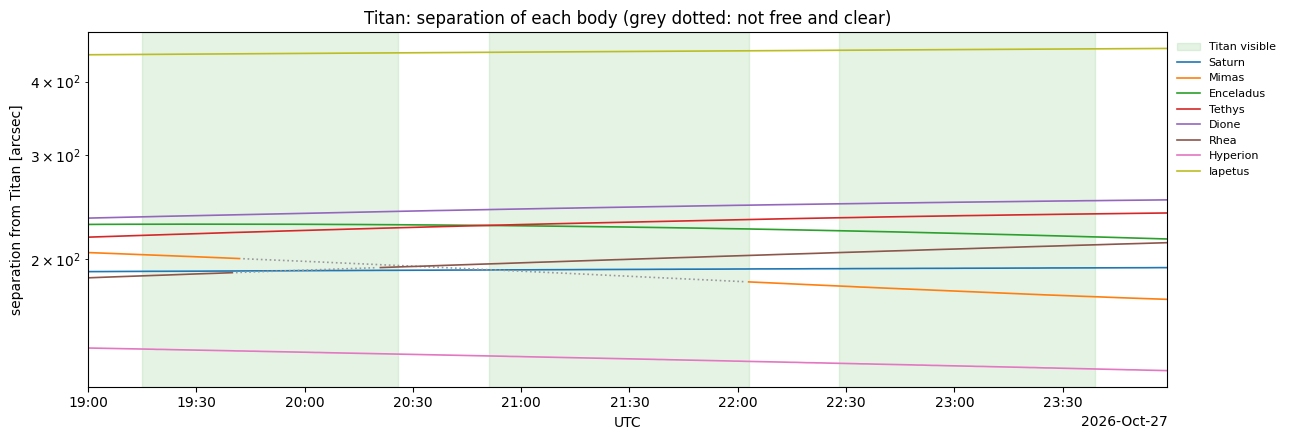

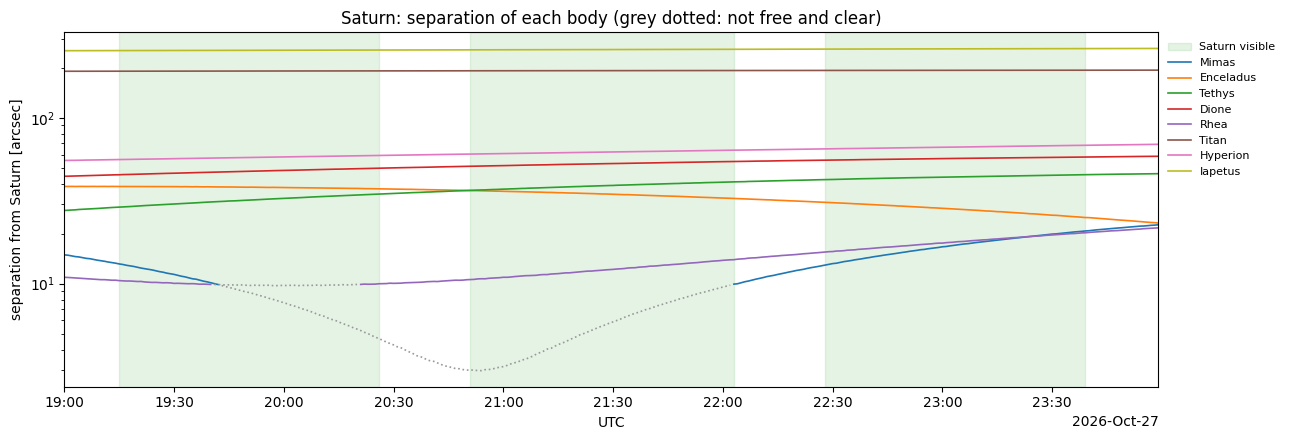

In [5]:
# Table rows every print_step_minutes (rounded to a multiple of the cadence)
print_step_minutes = 120.0
every = max(1, int(round(print_step_minutes / time_step_minutes)))
dates = times.to_datetime()

for target_id, label in targets:
    ephemeris = ephemerides[target_id]
    visible = results[label]["visible"]
    pointing = SkyCoord(*pandora_centric(ephemeris, visibility, times), unit="deg")
    geocentric = SkyCoord(ephemeris["ra"], ephemeris["dec"], unit="deg")
    others = [body_id for body_id in system_ids(target_id) if body_id != target_id]
    separation = {
        body_id: geocentric.separation(
            SkyCoord(ephemerides[body_id]["ra"], ephemerides[body_id]["dec"], unit="deg")
        ).arcsec
        for body_id in others
    }
    clear = {body_id: is_clear(body_id, ephemerides[body_id]) for body_id in others}
    rate = pointing[1:].separation(pointing[:-1]).arcsec / (time_step_minutes / 60.0)
    # The pointing as an ICRF (J2000 ECI) unit vector, one (x, y, z) row per step
    unit_xyz = pointing.cartesian.xyz.value.T

    print(f"\n{label}: Pandora-centric pointing (astrometric ICRF) and "
          f"separations of the other bodies [arcsec]")
    print(f"  moves {np.median(rate):.1f}\"/h on the sky (up to {rate.max():.1f}\"/h); "
          f"Pandora's parallax shifts it up to "
          f"{pointing.separation(geocentric).arcsec.max():.1f}\" from the geocentric position")
    print("  x, y, z: the pointing as a J2000 ECI (ICRF) unit vector")
    print(f"  {'UTC':<17}{'vis':>4}{'RA [deg]':>12}{'Dec [deg]':>11}"
          f"{'x':>17}{'y':>17}{'z':>17}   "
          f"{'RA (hms)':<14}{'Dec (dms)':<14}"
          + "".join(f"{labels[body_id]:>12}" for body_id in others))
    for index in range(0, len(times), every):
        ra_hms, dec_dms = pointing[index].to_string("hmsdms", precision=1).split()
        row = "".join(
            f"{separation[body_id][index]:>10.1f} "
            f"{'' if clear[body_id][index] else ephemerides[body_id]['code'][index]:1}"
            for body_id in others
        )
        print(f"  {times[index].iso[:16]:<17}{'yes' if visible[index] else '':>4}"
              f"{pointing[index].ra.deg:>12.5f}{pointing[index].dec.deg:>+11.5f}"
              + "".join(f"{value:>+17.12f}" for value in unit_xyz[index]) + "   "
              f"{ra_hms:<14}{dec_dms:<14}{row}")

    fig, ax = plt.subplots(figsize=(13, 4.5))
    ax.fill_between(dates, 0, 1, where=visible, transform=ax.get_xaxis_transform(),
                    color="tab:green", alpha=0.12, step="mid", label=f"{label} visible")
    # tab10 without its grey, which here means "not free and clear"
    colors = [c for i, c in enumerate(plt.cm.tab10.colors) if i != 7]
    for body_id, color in zip(others, colors):
        ax.plot(dates, np.where(clear[body_id], separation[body_id], np.nan),
                lw=1.2, color=color, label=labels[body_id])
        ax.plot(dates, np.where(clear[body_id], np.nan, separation[body_id]),
                lw=1.2, color="0.6", linestyle=":")
    ax.set_yscale("log")
    ax.set_ylabel(f"separation from {label} [arcsec]")
    ax.set_title(f"{label}: separation of each body (grey dotted: not free and clear)")
    format_date_axis(ax, times)
    ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8, frameon=False)
    plt.tight_layout()

## When is each target visible, and which bodies are clear?

One plot per target. The first row is the target itself; the rows below are the other bodies of its system. A blue box marks when that body is free and clear (not transiting, occulted or eclipsed; a planet always is), and the green line marks when it is **observable**: the target is visible *and* that body is clear. For a moon target, its own row therefore shows when it can actually be observed; for a planet target, the moon rows show when each moon is in view beside it.



 606 Titan
2026-10-27T19:00:00.000: False 115.0
2026-10-27T19:01:00.000: False 115.0
2026-10-27T19:02:00.000: False 115.0
2026-10-27T19:03:00.000: False 115.0
2026-10-27T19:04:00.000: False 115.0
2026-10-27T19:05:00.000: False 115.0
2026-10-27T19:06:00.000: False 115.0
2026-10-27T19:07:00.000: False 115.0
2026-10-27T19:08:00.000: False 115.0
2026-10-27T19:09:00.000: False 115.0
2026-10-27T19:10:00.000: False 115.0
2026-10-27T19:11:00.000: False 115.0
2026-10-27T19:12:00.000: False 115.0
2026-10-27T19:13:00.000: False 115.0
2026-10-27T19:14:00.000: False 115.0
2026-10-27T19:15:00.000: True 115.0
2026-10-27T19:16:00.000: True 115.0
2026-10-27T19:17:00.000: True 115.0
2026-10-27T19:18:00.000: True 115.0
2026-10-27T19:19:00.000: True 115.0
2026-10-27T19:20:00.000: True 115.0
2026-10-27T19:21:00.000: True 115.0
2026-10-27T19:22:00.000: True 115.0
2026-10-27T19:23:00.000: True 115.0
2026-10-27T19:24:00.000: True 115.0
2026-10-27T19:25:00.000: True 115.0
2026-10-27T19:26:00.000: True 115.0


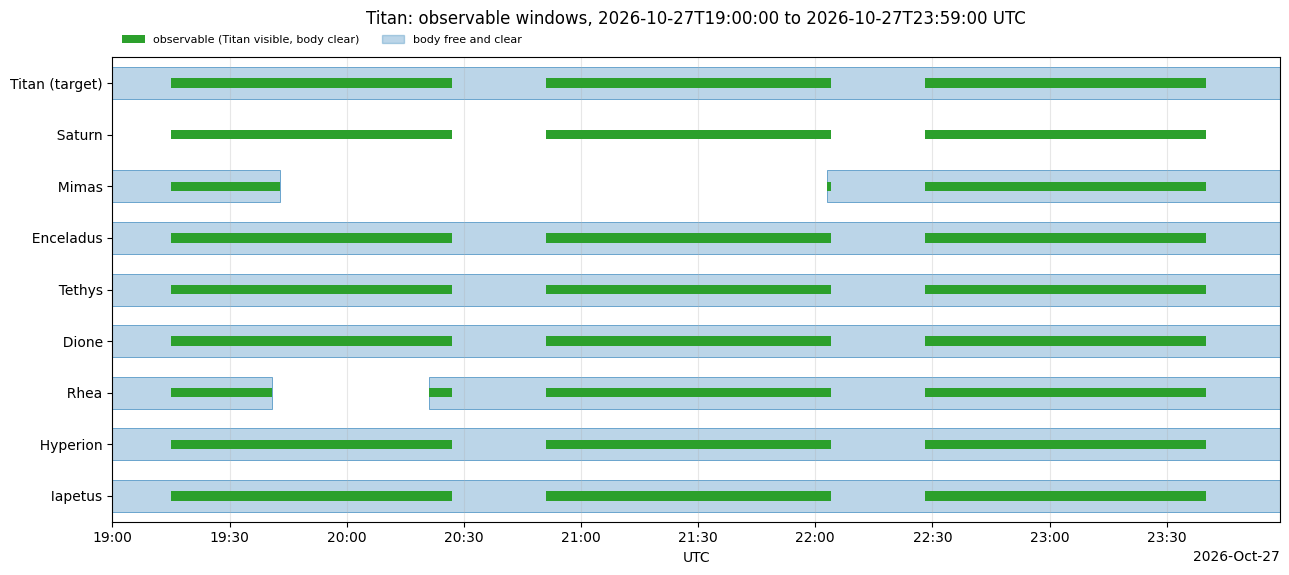

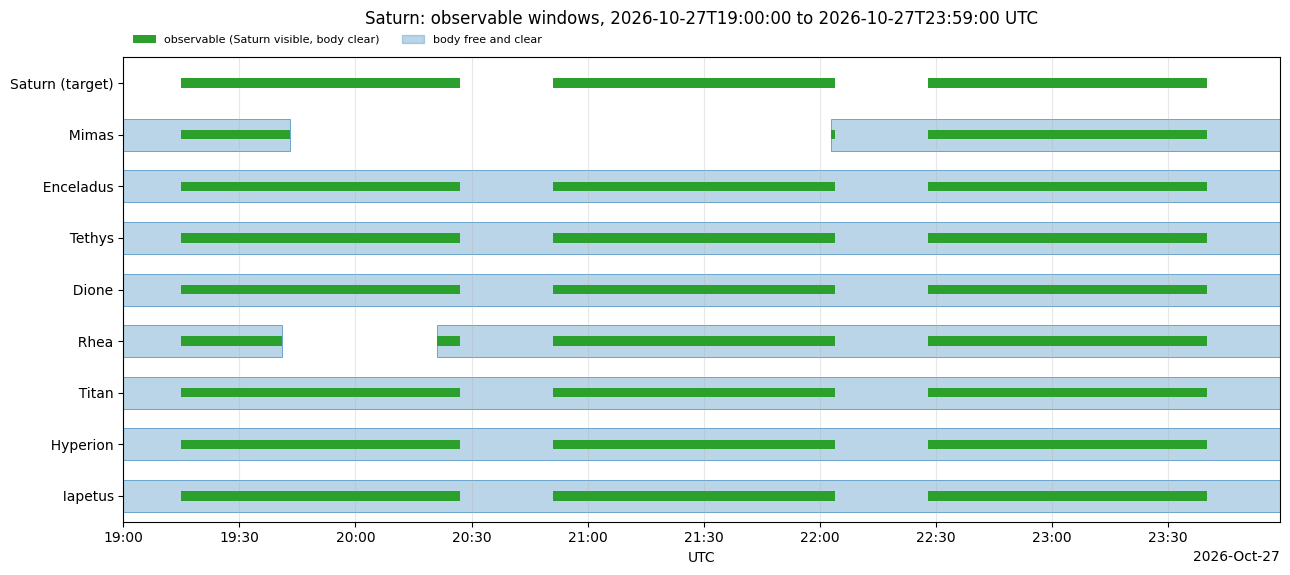

In [6]:
CLEAR_COLOR = "tab:blue"

for target_id, label in targets:
    result = results[label]
    bodies = [target_id] + [b for b in system_ids(target_id) if b != target_id]
    fig, ax = plt.subplots(figsize=(13, 0.45 * len(bodies) + 1.8))
    for row, body_id in enumerate(bodies):
        clear = is_clear(body_id, ephemerides[body_id])
        if body_id % 100 != 99:
            draw_event_box(
                ax, row, mask_segments(times, clear, time_step_minutes), CLEAR_COLOR
            )
        draw_row(
            ax, row,
            mask_segments(times, result["visible"] & clear, time_step_minutes),
            "tab:green",
        )
    label_rows(ax, [labels[target_id] + " (target)"]
               + [f"  {labels[body_id]}" for body_id in bodies[1:]])
    format_date_axis(ax, times)
    ax.set_title(f"{label}: observable windows, {start_utc} to {stop_utc} UTC", pad=24)
    handles = [
        Patch(facecolor="tab:green", label=f"observable ({label} visible, body clear)"),
        Patch(facecolor=CLEAR_COLOR, alpha=0.30, edgecolor=CLEAR_COLOR,
              label="body free and clear"),
    ]
    ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0.0, 1.005),
              ncols=len(handles), fontsize=8, frameon=False)
    plt.tight_layout()
for target_id, label in targets:
    print("\n\n", target_id, label)
    result = results[label]
    for time, vis, roll in zip(times, result["visible"], result['roll_deg']):
        print(f"{time}: {vis} {roll}")

## Which constraint is failing?

As in `target_visibility.ipynb`: for each target, a bar marks the time steps where that row fails, and the grey row at the bottom is the overall "not visible" result. **Red rows are binding**; **amber rows are per-tracker detail**, binding only when no other tracker covers them (`st_required`). These are the pointing constraints only: whether a moon is occulted or eclipsed is shown in Cell 6, not here.

Titan: not visible at 83 of 300 steps
    moon           fails at     0 steps
    sun            fails at     0 steps
    earthlimb      fails at    69 steps
    star tracker   fails at    83 steps (needs either tracker)
      ST1 sun      < 50 deg at     0 steps
      ST1 moon     < 20 deg at     0 steps
      ST1 limb     < 30 deg at   166 steps
      ST2 sun      < 50 deg at     0 steps
      ST2 moon     < 20 deg at     0 steps
      ST2 limb     < 30 deg at   165 steps
Saturn: not visible at 83 of 300 steps
    moon           fails at     0 steps
    sun            fails at     0 steps
    earthlimb      fails at    69 steps
    star tracker   fails at    83 steps (needs either tracker)
      ST1 sun      < 50 deg at     0 steps
      ST1 moon     < 20 deg at     0 steps
      ST1 limb     < 30 deg at   166 steps
      ST2 sun      < 50 deg at     0 steps
      ST2 moon     < 20 deg at     0 steps
      ST2 limb     < 30 deg at   165 steps


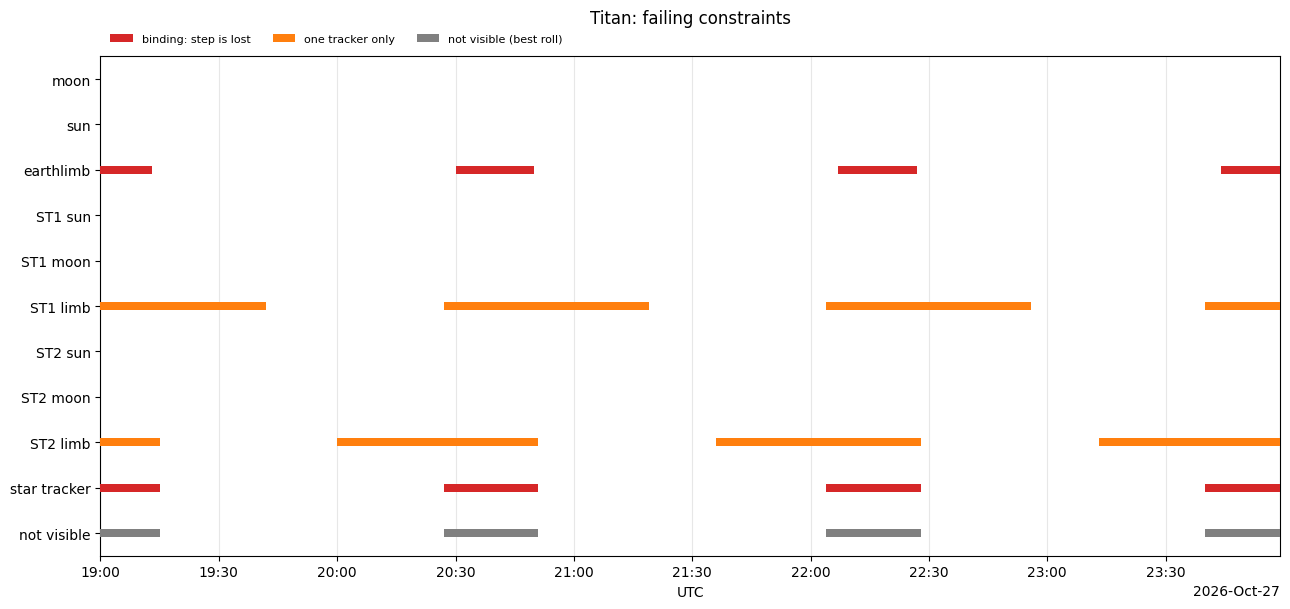

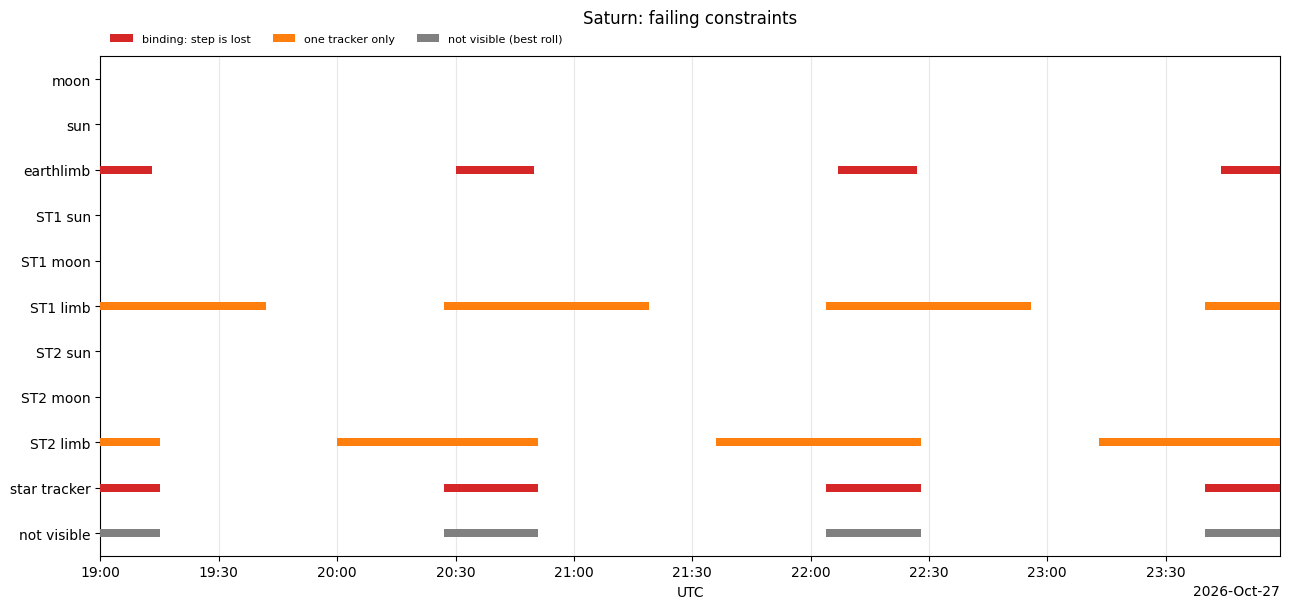

In [7]:
BINDING_COLOR = "tab:red"
TRACKER_COLOR = "tab:orange"

for label, result in results.items():
    not_visible = ~result["visible"]
    binding = {
        name.replace("_", " "): ~passed for name, passed in result["constraints"].items()
    }
    detail = {
        name: ~passed
        for name, passed in result["tracker_checks"].items()
        if name not in ("ST1", "ST2", "combined")
    }
    explained = np.zeros_like(not_visible)
    for fail_mask in binding.values():
        explained |= fail_mask
    unexplained = int(np.sum(not_visible & ~explained))

    boresight = [name for name in binding if name != "star tracker"]
    st_rows = ["star tracker"] if "star tracker" in binding else []
    rows = boresight + list(detail) + st_rows + ["not visible"]

    fig, ax = plt.subplots(figsize=(13, 0.4 * len(rows) + 1.8))
    for row, name in enumerate(rows):
        if name == "not visible":
            mask, color = not_visible, "0.5"
        elif name in detail:
            mask, color = detail[name], TRACKER_COLOR
        else:
            mask, color = binding[name], BINDING_COLOR
        draw_row(ax, row, mask_segments(times, mask, time_step_minutes), color)
    label_rows(ax, rows)
    format_date_axis(ax, times)
    ax.set_title(f"{label}: failing constraints", pad=24 if detail else 6)
    if detail:
        handles = [
            Patch(facecolor=BINDING_COLOR, label="binding: step is lost"),
            Patch(facecolor=TRACKER_COLOR, label="one tracker only"),
            Patch(facecolor="0.5", label="not visible (best roll)"),
        ]
        ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0.0, 1.005),
                  ncols=len(handles), fontsize=8, frameon=False)
    plt.tight_layout()

    print(f"{label}: not visible at {int(not_visible.sum())} of {len(times)} steps")
    for name in boresight:
        print(f"    {name:<14} fails at {int(binding[name].sum()):>5} steps")
    if detail:
        need = "both trackers" if visibility.st_required == 2 else "either tracker"
        print(f"    {'star tracker':<14} fails at "
              f"{int(binding['star tracker'].sum()):>5} steps (needs {need})")
        for name, mask in detail.items():
            print(f"      {name:<12} < {result['limits'][name].value:.0f} deg at "
                  f"{int(mask.sum()):>5} steps")
    if unexplained:
        print(f"    WARNING: {unexplained} not-visible steps are not explained "
              f"by any row above; the rows and the result have diverged")

## The NIRDA subarray each day

For each target and each day it is visible, the simulated `nirda_roi_x` x `nirda_roi_y` subarray at the roll held that day, at the middle visible time step (`trace.plot_trace`). The target sits at the pivot; the other bodies of its system and the Gaia field stars (J < 14) are drawn as traces, labeled by name or J. The dashed box is the target's extraction aperture, and each title gives the time, the roll and the trace contamination of that aperture (worst spectral channel, within ±1° of roll error).

Approximations, all in `solar_system_helpers.py`:
- A body wider than two pixels (here only the planet) is a uniform oblate disk, plus Saturn's A and B rings at the Horizons ring opening angle with the disk's surface brightness. Ring shadows, the disk hidden behind the rings and limb darkening are ignored.
- Brightness ratios use J = V - 1.15 (sunlight's color) from Horizons' visual magnitudes. Methane bands make Saturn and Titan fainter in the near infrared than that.
- A moon occulted by its planet or fully eclipsed is left out of the panel; a partially eclipsed or transiting moon is drawn at its Horizons magnitude.

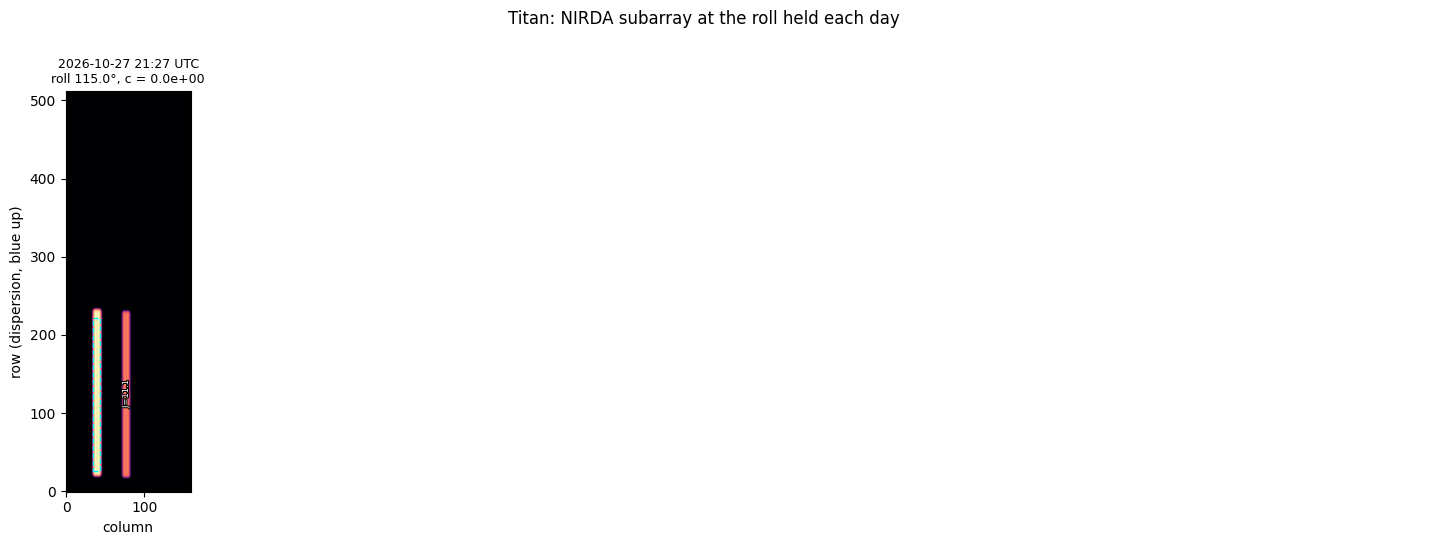

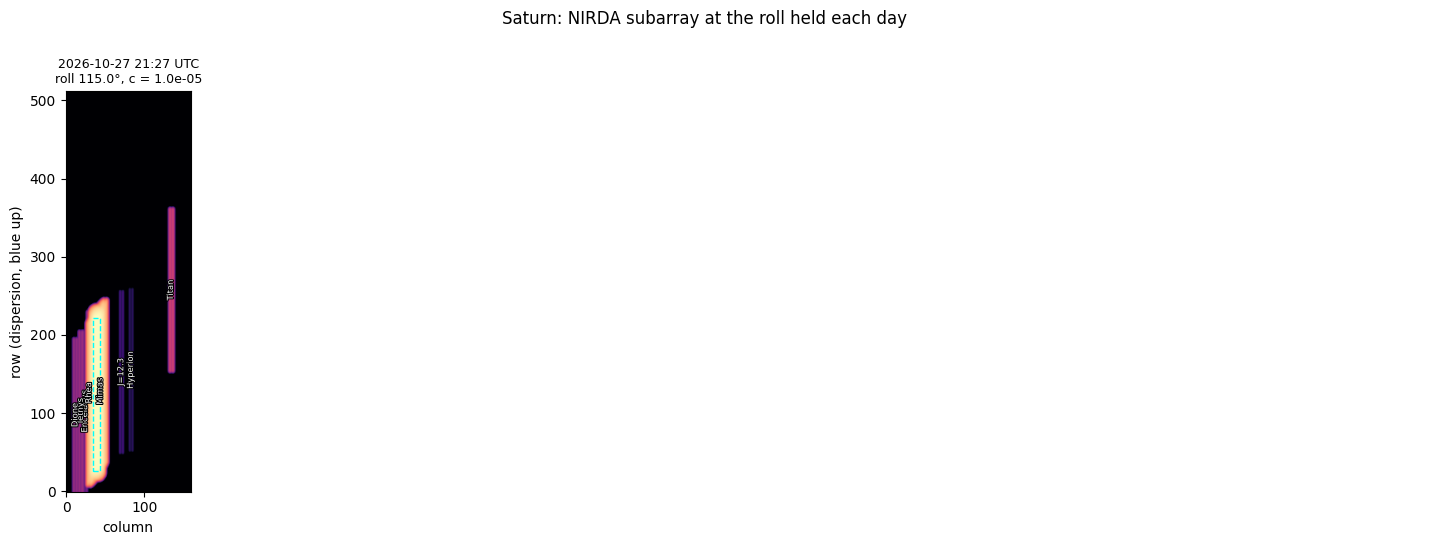

In [8]:
n_columns = 7
for target_id, label in targets:
    result = results[label]
    # Middle visible step of each day
    panels = []
    for day in days:
        indices = np.flatnonzero((day_of == day) & result["visible"])
        if indices.size:
            panels.append(indices[indices.size // 2])
    if not panels:
        print(f"{label}: not visible on any day, so no subarray panels")
        continue

    n_rows = int(np.ceil(len(panels) / n_columns))
    fig, axes = plt.subplots(
        n_rows, n_columns, figsize=(2.1 * n_columns, 5.4 * n_rows), squeeze=False
    )
    for ax, index in zip(axes.flat, panels):
        field = system_field(
            target_id, ephemerides, index, times[index], labels,
            include_stars=include_field_stars,
        )
        trace.plot_trace(
            field,
            result["roll_deg"][index] * u.deg,
            visibility.nirda_roi_x,
            visibility.nirda_roi_y,
            ax=ax,
            title=f"{times[index].iso[:16]} UTC",
        )
    for ax in axes.flat[len(panels):]:
        ax.set_axis_off()
    fig.suptitle(f"{label}: NIRDA subarray at the roll held each day", y=1.0)
    plt.tight_layout()

## The VISDA field each day

For each target and each day it is visible, the simulated VISDA (visible camera) field at the roll held that day and the same time step as the NIRDA panels (`visda.plot_visible_field`), as one uncoadded 0.2 s frame with read noise. The target is centered in the red box (`visda_target_box` pixels, at `visda_target_pixel`, None for the field center), and the blue box is `visda_center_box` pixels about the field center. The bodies of its system that are not hidden are drawn with the same disk and ring samples as the NIRDA panels and labeled by name, and Gaia stars brighter than `visda_bp_limit` in BP are added (labeled when brighter than BP 12). White contours outline where the model saturates (a planet's disk and rings), and orange circles mark stars whose brightest pixel likely saturates. The camera model is described in `target_visibility.ipynb`.

Bodies take Gaia G = V - 0.15 and BP - RP = 0.82 (sunlight's color) from Horizons' visual magnitudes.

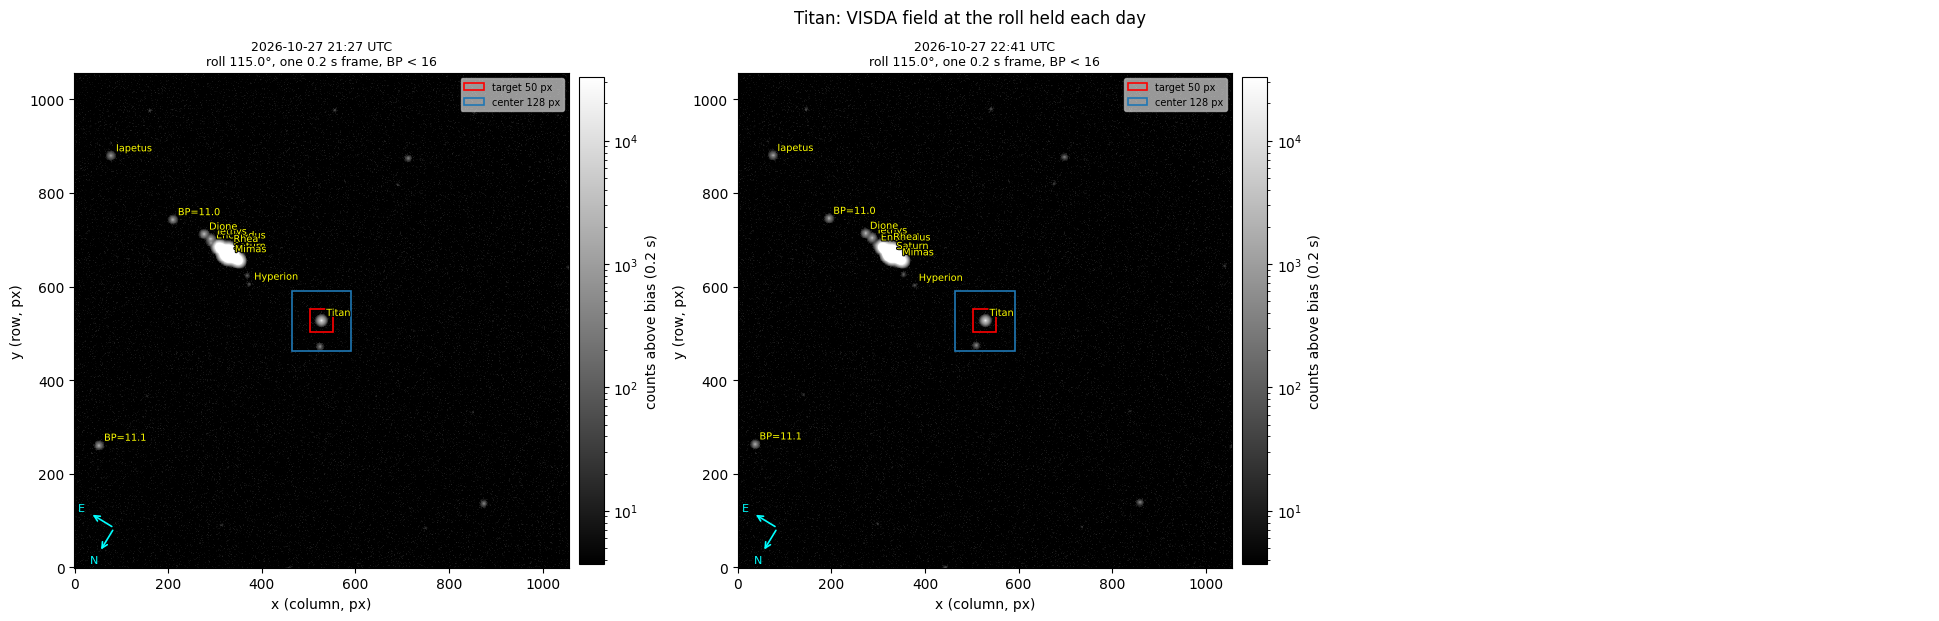

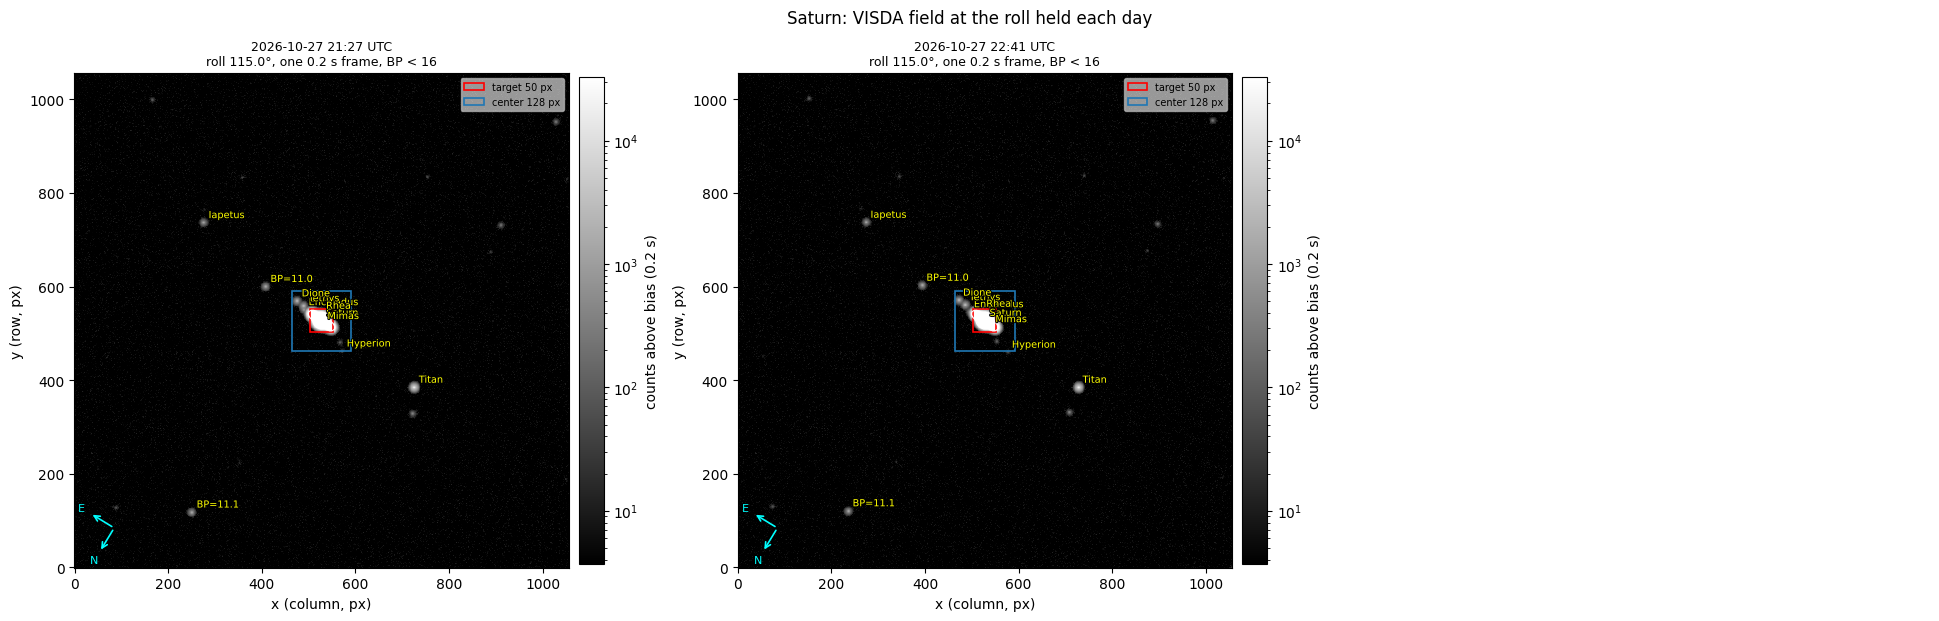

In [9]:
# VISDA field settings, as in target_visibility.ipynb: the field's (x, y) size
# in pixels; the target's pixel in it (None for the field center); the sides
# in pixels of the red box on the target and the blue box on the field center;
# and the faintest Gaia BP drawn.
visda_field_size = (1056, 1056)
visda_target_pixel = None
visda_target_box = 50
visda_center_box = 128
visda_bp_limit = 16.0

radius_arcmin = visda.field_radius_arcmin(visda_field_size, visda_target_pixel)
n_columns = 3
for target_id, label in targets:
    result = results[label]
    # Middle visible step of each day, as in the NIRDA panels
    panels = []
    for day in days:
        indices = np.flatnonzero((day_of == day) & result["visible"])
        if indices.size:
            panels.append(indices[indices.size // 2])
            panels.append(indices[indices.size // 2 + 50])
    if not panels:
        print(f"{label}: not visible on any day, so no VISDA panels")
        continue

    n_rows = int(np.ceil(len(panels) / n_columns))
    fig, axes = plt.subplots(
        n_rows, n_columns, figsize=(6.5 * n_columns, 6.0 * n_rows), squeeze=False
    )
    for ax, index in zip(axes.flat, panels):
        sources = system_visible_sources(
            target_id, ephemerides, index, times[index], labels, radius_arcmin,
            include_stars=include_field_stars,
        )
        visda.plot_visible_field(
            sources,
            result["roll_deg"][index] * u.deg,
            field_size=visda_field_size,
            target_pixel=visda_target_pixel,
            target_box=visda_target_box,
            center_box=visda_center_box,
            bp_limit=visda_bp_limit,
            ax=ax,
            title=f"{times[index].iso[:16]} UTC",
        )
    for ax in axes.flat[len(panels):]:
        ax.set_axis_off()
    fig.suptitle(f"{label}: VISDA field at the roll held each day", y=1.0)
    plt.tight_layout()

## Save one CSV per target

One row per time step of Cell 2's grid, written beside this notebook as `<target>.csv` (git ignores `docs/*.csv`), overwriting an earlier run's file:

- `datetime`: UTC, ISO format
- `visible`: True or False
- `RA`, `DEC`: the Pandora-centric pointing at that step (as in Cell 5) in decimal degrees
- `X`, `Y`, `Z`: the same direction as a J2000 ECI (ICRF) unit vector, 12 decimals
- `Roll`: the roll held, in degrees (the roll held that day, as in Cell 4)


In [10]:
# One CSV per target, written beside this notebook
for target_id, label in targets:
    result = results[label]
    ra_deg, dec_deg = pandora_centric(ephemerides[target_id], visibility, times)
    unit_xyz = SkyCoord(ra_deg, dec_deg, unit="deg").cartesian.xyz.value.T
    path = Path(f"{label.replace(' ', '_')}.csv")
    with open(path, "w", newline="") as file:
        writer = csv.writer(file)
        writer.writerow(["datetime", "visible", "RA", "DEC", "X", "Y", "Z", "Roll"])
        for index, time in enumerate(times.isot):
            writer.writerow(
                [time, bool(result["visible"][index]),
                 f"{ra_deg[index]:.8f}", f"{dec_deg[index]:.8f}"]
                + [f"{value:.12f}" for value in unit_xyz[index]]
                + [f"{result['roll_deg'][index]:.4f}"]
            )
    print(f"{label}: {len(times)} rows -> {path.resolve()}")

Titan: 300 rows -> C:\Gits\pandora-visibility\docs\Titan.csv
Saturn: 300 rows -> C:\Gits\pandora-visibility\docs\Saturn.csv
